# HW Y · 04 — Round 4: consistent distillation (the teacher sees the student's view)

Until Round 3, every training image had **one fixed soft label**: the teacher ensemble's TTA-20 prediction on the
whole image. The student sees a different random crop, flip and colour jitter every epoch, so a crop that cuts off the
lesion border is still asked to match the whole-image prediction. Beyer et al. (CVPR 2022, *A good teacher is patient
and consistent*) find that the teacher should see **the same view** as the student.

**Method** (`scripts/teacher_views.py`, `train_classifier.py --teacher-views`):
1. Draw 16 random training views per image once (same distribution as the training pipeline) and store their parameters.
2. The out-of-fold 5-backbone teacher (HW X fold models that never saw the image) predicts each view.
3. Calibrate each member with one temperature, average, renormalise.
4. Each epoch the student draws one of the 16 views and trains on it with that view's soft label.

**Runs** (all full frame + EMA, as the adopted recipe), pre-registered in `research/plan.md`:
fixed labels seeds 0/1 (control), consistent labels seeds 0/1, consistent labels with α = 0.9.

**Rule:** average the two seeds of each arm per fold; adopt consistent targets if the paired CV gain is > 0 with
≥ 3/5 folds better.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWY_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWY_DIR)); sys.path.insert(0, str(HWY_DIR / "research"))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
la = lambda r: f"{r}_tta20_la"
BASE, R1_RECT, ADOPTED = "hwx/convnext_s_kd_res448_tta20_la", "cnx_kd_r1_rect_tta20_la", "cnx_kd_r1_rect_ema_tta20_la"

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWY_DIR)

TV = HWY_DIR / "results" / "teacher_views" / "bb5_rect_v16"
RUN_TEACHER = False   # True on a GPU node: teacher predictions for one CV fold (~12 min), then merge (CPU, ~1 min)
if RUN_TEACHER:
    run(f"python scripts/teacher_views.py predict --out {TV} --fold 0")
    run(f"python scripts/teacher_views.py merge --out {TV}")
RUN_TRAINING = False  # True on a GPU node: one fold of the consistent-distillation student (~42 min)
if RUN_TRAINING:
    run("python scripts/train_classifier.py --run-name cnx_kd_r4_cons --model convnext_small.fb_in22k_ft_in1k --lr 2e-4 "
        f"--img-size 448 --img-width 600 --teacher-views {TV} --kd-alpha 0.5 --ema 0.999 --fold 0")

## The teacher on stored views: how different are per-view targets from the fixed target?

In [2]:
summary = json.loads((TV / "summary.json").read_text())
display(pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)}).round(4).to_frame("value"))
display(pd.DataFrame({"temperature": summary["temperatures"], "per-view balanced acc": summary["per_view_member_bacc"]}).round(3))

,value
per_view_ensemble_bacc,0.8065
view_avg_ensemble_bacc,0.8173
fixed_label_bacc,0.8233
tv_to_fixed_mean,0.0452
tv_to_fixed_median,0.0110
p_true_view_mean,0.8464
p_true_fixed_mean,0.8588
p_true_within_image_sd_mean,0.0324
argmax_changes_across_views,0.1187
per_view_argmax_vs_fixed_disagree,0.0384


,temperature,per-view balanced acc
resnet50_ce_res448,1.725,0.746
convnext_s_res448,2.164,0.772
effv2_s_res448,2.498,0.754
dinov2_b14_res448,2.184,0.760
vit_b16_res448,2.506,0.760


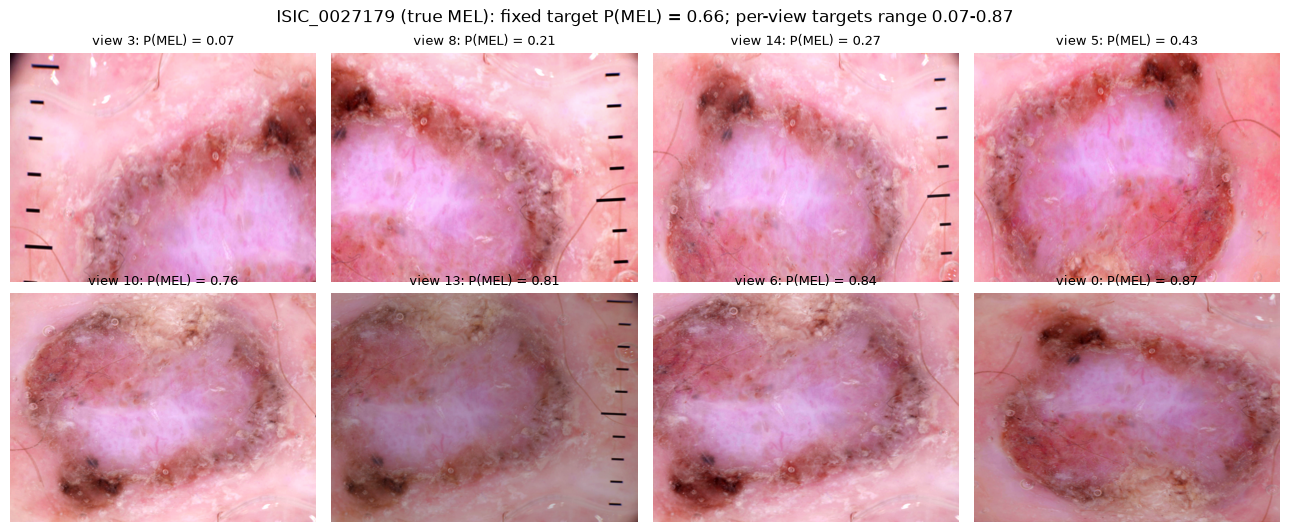

In [3]:
from PIL import Image
from isic.data import apply_view, load_split, IMAGENET_MEAN, IMAGENET_STD
df = pd.read_csv(TV / "images.csv"); params = np.load(TV / "params.npy"); soft = np.load(TV / "soft_views.npy")
fixed = pd.read_csv(HWY_DIR / "results/hwx/soft_labels/bb5_calib_oof.csv").set_index("image").loc[df.image, CLASSES].to_numpy()
y = df.label.to_numpy(); p_true = soft[np.arange(len(df)), :, y]
i = int(np.argmax(p_true.std(1) * (y == 0)))   # the melanoma whose views disagree most
paths = load_split("train").set_index("image").path
img = Image.open(paths[df.image[i]]).convert("RGB")
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4))
for ax, v in zip(axes.flat, np.argsort(p_true[i])[[0, 1, 2, 3, -4, -3, -2, -1]]):
    x = apply_view(img, params[i, v], (448, 600)).permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    ax.imshow(x.clip(0, 1)); ax.axis("off"); ax.set_title(f"view {v}: P(MEL) = {p_true[i, v]:.2f}", fontsize=9)
fig.suptitle(f"{df.image[i]} (true MEL): fixed target P(MEL) = {fixed[i, 0]:.2f}; per-view targets range "
             f"{p_true[i].min():.2f}-{p_true[i].max():.2f}"); plt.tight_layout()

## Results

In [4]:
NAMES = {"fixed targets, seed 0": "cnx_kd_r1_rect_ema", "fixed targets, seed 1": "cnx_kd_r1_rect_s1_ema",
         "consistent, seed 0": "cnx_kd_r4_cons_ema", "consistent, seed 1": "cnx_kd_r4_cons_s1_ema",
         "consistent, alpha 0.9": "cnx_kd_r4_cons_a09_ema"}
runs = [BASE] + [la(r) for r in NAMES.values()]
display(A.summary(runs, names=["baseline (HW X)"] + list(NAMES))[["bal_acc", "auc", "mel_sens"]])
display(A.summary(runs, split="cv_val", names=["baseline (HW X)"] + list(NAMES), ensemble=False)[["bal_acc"]].rename(columns={"bal_acc": "cv_bal_acc"}))

,bal_acc,auc,mel_sens
baseline (HW X),0.864 ± 0.010,0.983 ± 0.001,0.795 ± 0.018
"fixed targets, seed 0",0.867 ± 0.004,0.983 ± 0.000,0.816 ± 0.005
"fixed targets, seed 1",0.850 ± 0.005,0.984 ± 0.001,0.828 ± 0.011
"consistent, seed 0",0.870 ± 0.005,0.983 ± 0.000,0.799 ± 0.011
"consistent, seed 1",0.866 ± 0.006,0.984 ± 0.001,0.801 ± 0.010
"consistent, alpha 0.9",0.860 ± 0.003,0.983 ± 0.000,0.742 ± 0.009


,cv_bal_acc
baseline (HW X),0.888 ± 0.020
"fixed targets, seed 0",0.894 ± 0.015
"fixed targets, seed 1",0.879 ± 0.015
"consistent, seed 0",0.907 ± 0.010
"consistent, seed 1",0.900 ± 0.005
"consistent, alpha 0.9",0.914 ± 0.013


In [5]:
run("python research/round4_analysis.py")

$ python research/round4_analysis.py


model            fixed targets, seed 0 (Round-3 model) fixed targets, seed 1 consistent targets, seed 0 consistent targets, seed 1 consistent targets, alpha 0.9, seed 0
cv                                            0.893792              0.879041                   0.907002                   0.899585                              0.913875
test                                          0.866944              0.850143                   0.869766                   0.865605                              0.860349
test_auc                                      0.983354              0.984304                   0.983265                   0.984262                              0.983483
test_mel_sens                                 0.816374               0.82807                    0.79883                    0.80117                               0.74152
cv vs R3 model                           +0.0000 (0/5)         -0.0148 (0/5)              +0.0132 (4/5)              +0.0058 (2/5)                         

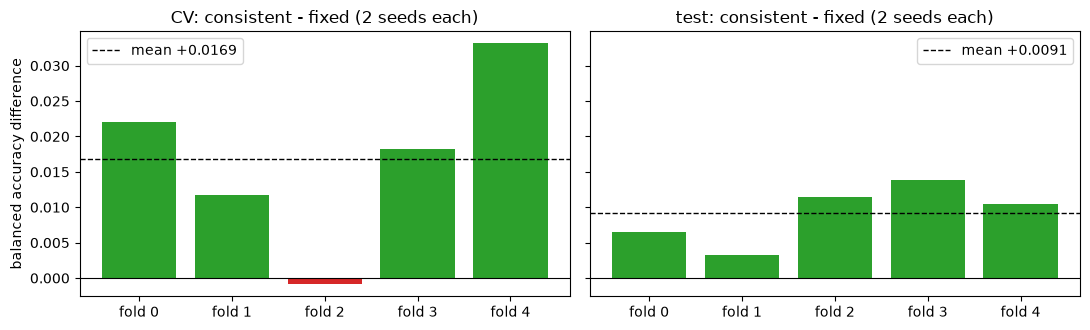

In [6]:
r4 = json.loads((HWY_DIR / "results/comparisons/hwy_round4.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, s, lab in ((axes[0], "cv_val", "CV"), (axes[1], "official_test", "test")):
    d = np.array(r4["primary"][s]["fold_diffs"])
    ax.bar(range(5), d, color=["C2" if v > 0 else "C3" for v in d]); ax.axhline(0, color="k", lw=.8)
    ax.axhline(d.mean(), color="k", ls="--", lw=1, label=f"mean {d.mean():+.4f}")
    ax.set_xticks(range(5), [f"fold {k}" for k in range(5)]); ax.set_title(f"{lab}: consistent - fixed (2 seeds each)"); ax.legend()
axes[0].set_ylabel("balanced accuracy difference"); plt.tight_layout()

In [7]:
noise = pd.DataFrame({s: r4["noise"]["pooled"][s]["seed_diffs"] for s in ("cv_val", "official_test")},
                     index=["fixed targets", "consistent targets", "Round 2: drop path 0.2"])
display(noise.round(4).rename(columns={"cv_val": "CV: seed 1 - seed 0", "official_test": "test: seed 1 - seed 0"}))
display(pd.Series(r4["cv_test_gap"]).round(4).to_frame("CV - test gap"))

,CV: seed 1 - seed 0,test: seed 1 - seed 0
fixed targets,-0.0148,-0.0168
consistent targets,-0.0074,-0.0042
Round 2: drop path 0.2,-0.0142,-0.0084


,CV - test gap
cnx_kd_r1_rect_ema,0.0268
cnx_kd_r1_rect_s1_ema,0.0289
cnx_kd_r4_cons_ema,0.0372
cnx_kd_r4_cons_s1_ema,0.0340
cnx_kd_r4_cons_a09_ema,0.0535


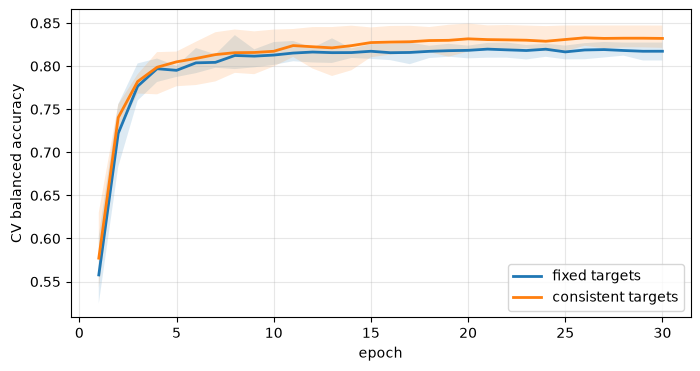

In [8]:
A.plot_curves(plt.subplots(figsize=(8, 4))[1], ["cnx_kd_r1_rect", "cnx_kd_r4_cons"], names=["fixed targets", "consistent targets"],
              metric="val_balanced_acc_ema")

## Takeaways (pre-registered rules, `research/plan.md` Round 4 outcome)
1. **Consistent distillation is adopted.** Two seeds per arm, paired by fold: CV **+0.017 (4/5 folds)**, test
   +0.009 (5/5), cross-fitted CV (seed 1) +0.008 (4/5). 2-seed test means: fixed 0.858, consistent 0.868.
   The per-view targets differ only slightly from the fixed ones (mean total variation 0.045, 3.8 % of views change the
   teacher's top class), yet matching the view helps.
2. **α 0.9 is adopted by the rule but does not hold up.** CV +0.007 (5/5), within the single-seed noise floor; test
   −0.009 (0/5) and melanoma sensitivity drops 0.80 → 0.74. Per rule 4 it is the Round-4 model: CV 0.914, test 0.860
   (95 % CI 0.833–0.885).
3. **Seed noise is larger than assumed.** Pooled over three seed pairs, the 5-fold mean of one run has SD ≈ 0.009 (CV)
   and 0.008 (test). The Round-3 model was a lucky seed (its seed-1 twin: test 0.850).
4. **CV grows optimistic as the student relies more on the teacher** (CV − test gap 0.027 → 0.036 → 0.054 for fixed,
   consistent, α 0.9), consistent with the out-of-fold teacher having seen the student's CV images.